## Visualize ensemble reconstruction results

In [17]:
import jax
jax.config.update('jax_platform_name', 'cpu')
import os 
os.environ['CUDA_VISIBLE_DEVICES'] = ''

import sys 
sys.path.insert(1, '../')

import plotly.graph_objs as go
from plotly.offline import iplot

from jax import numpy as jnp
import numpy as np

from scipy.ndimage import gaussian_filter

import matplotlib.pyplot as plt
import matplotlib as mpl

from tqdm.notebook import tqdm

from functools import partial

In [33]:
mpl.rcParams.update({
    "axes.unicode_minus": False,
    "font.family": "serif",
    "font.serif": ["STIXGeneral", "DejaVu Serif", "Times New Roman", "Times"],
    "mathtext.fontset": "stix",   # STIX math
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

In [18]:
pm_seed = 4
# num_its = 25
# i_list = range(64)
i_list = range(128)
# i_list = range(1)
# i_list = list(range(0, 0+num_its)) + list(range(25, 25+num_its)) + list(range(50, 50+num_its)) + list(range(75, 75+num_its))
save_dirs = ['../../exp/vol_jwst%d_L_2_Lz_5_proj_gg_shape_sigma_0.25_lam_0.001/%d'%(pm_seed, i) for i in i_list]

# wiener_recon = jnp.load('../../wiener_recon/pm%d_wiener.npy'%pm_seed).transpose((1,2,0))
wiener_recon = jnp.load('/srv/tmp/brandon/abacus/wiener_recon/wiener_jwst_4.npy').transpose(1, 2, 0)
print(wiener_recon.shape)
ddpm_recon = jnp.load('/srv/tmp/brandon/abacus/wiener_recon/ddpm_jwst_4.npy')[:, 20:89, -69:] .transpose(1, 2, 0)
ddpm_samples = jnp.load('/srv/tmp/brandon/abacus/wiener_recon/ddpm_jwst_4_samples.npy')[:, :, 20:89, -69:].transpose(0, 2, 3, 1)
density_paths = [save_dir + '/density/density_500.p' for save_dir in save_dirs]
# density_paths_2 = [save_dir + '/density/density_500.p' for save_dir in save_dirs_2]

daps_recon = jnp.load('/srv/tmp/brandon/abacus/wiener_recon/ddpm_jwst_4_nops.npy')[:, 20:89, -69:] .transpose(1, 2, 0)

res = 69

(69, 69, 20)


In [19]:
for density_path in density_paths: 
    if not os.path.exists(density_path):
        print(density_path)

In [20]:
def mean_subtract(vol, axis=(0,1)): 
    return vol - jnp.mean(vol, axis=axis, keepdims=True)

densities = [mean_subtract(jnp.load(density_path).reshape(res, res, 20)) for density_path in density_paths]
densities_arr = jnp.array(densities)

density_gt = jnp.load(save_dirs[-1] + '/../density_gt.p').reshape(res, res, 20)

pws = jnp.load(save_dirs[0] + '/../pws.npy')
pws_ein = pws.reshape(-1, res, res, 20)

density_gt = mean_subtract(density_gt)
ddpm_recon = mean_subtract(ddpm_recon)
wiener_recon = mean_subtract(wiener_recon)

print(ddpm_recon.shape)
print(wiener_recon.shape)

(69, 69, 20)
(69, 69, 20)


In [21]:
k_gt = jnp.einsum('nhwc,hwc->nhw', pws_ein, density_gt).mean(0)
k_nn = jnp.einsum('nhwc,mhwc->mnhw', pws_ein, densities_arr).mean(1)
k_dm = jnp.einsum('nhwc,hwc->nhw', pws_ein, ddpm_recon).mean(0)
# k_daps = jnp.einsum('nhwc,hwc->nhw', pws_ein, daps_recon).mean(0)
k_wiener = jnp.einsum('nhwc,hwc->nhw', pws_ein, wiener_recon).mean(0)

k_dm_samples = jnp.einsum('nhwc,mhwc->mnhw', pws_ein, ddpm_samples).mean(1)

In [22]:
print(k_gt.max(), k_gt.min())

vmin, vmax = k_gt.min(), k_gt.max()

0.6944256 -0.032238137


In [23]:
densities_median = jnp.median(densities_arr, axis=0)
densities_mean = jnp.mean(densities_arr, axis=0)
densities_std = jnp.std(densities_arr, axis=0)

print(densities_mean.shape)

(69, 69, 20)


In [24]:
def get_mse(gt, recon): 
    gt = mean_subtract(gt)
    recon = mean_subtract(recon)
    return np.mean(np.square(gt - recon))

def get_psnr(gt, recon):
    mse = get_mse(gt, recon)
    max_val = mean_subtract(gt).max()
    psnr = 10 * np.log10(max_val ** 2 / (mse + 1e-10))
    return psnr

def get_pcc(gt, recon):
    gt = mean_subtract(gt).flatten()
    recon = mean_subtract(recon).flatten()
    return np.corrcoef(gt, recon)[0, 1]

def lightcone_avg(metric, gt, recon, return_metrics=False):
    metrics = np.array([metric(gt[..., i], recon[..., i]) for i in range(gt.shape[-1])])
    if return_metrics: 
        return np.mean(metrics, axis=0), metrics
    else: 
        return np.mean(metrics, axis=0)
    
def energy_score(gt, samples, feature=None):
    """
    Energy Score for samples ~ P vs. ground truth gt.
    Optionally pass feature(X) to compute ES in a feature space.
    """
    X = samples.reshape(len(samples), -1)
    y = gt.reshape(1, -1)
    if feature is not None:
        X = feature(X); y = feature(y)
    A = np.linalg.norm(X - y, axis=1).mean()                      # term (A)
    D = np.linalg.norm(X[:, None, :] - X[None, :, :], axis=-1).mean()  # term (B)
    return A - 0.5 * D
    
get_pcc_avg = partial(lightcone_avg, get_pcc)

In [25]:
density_gt_blur = gaussian_filter(density_gt, (0, 0, 4.), mode='constant')
ddpm_blur = gaussian_filter(ddpm_recon, (0, 0, 4.), mode='constant')
neur_blur = gaussian_filter(densities_mean, (0, 0, 4.), mode='constant')
wien_blur = gaussian_filter(wiener_recon, (0, 0, 4.), mode='constant')
# for n_planes in range(1, 21):
n_planes = 12
es_ddpm = energy_score(density_gt[..., :n_planes], ddpm_samples[..., :n_planes])
es_neur = energy_score(density_gt[..., :n_planes], densities_arr[..., :n_planes])

print(n_planes, es_ddpm, es_neur)

12 209.19642639160156 209.4799041748047


In [26]:
_, pcc_ours = lightcone_avg(get_pcc, density_gt[..., :12], ddpm_recon[..., :12], return_metrics=True)
_, pcc_wien = lightcone_avg(get_pcc, density_gt[..., :12], wiener_recon[..., :12], return_metrics=True)
_, pcc_neur = lightcone_avg(get_pcc, density_gt[..., :12], densities_mean[..., :12], return_metrics=True)

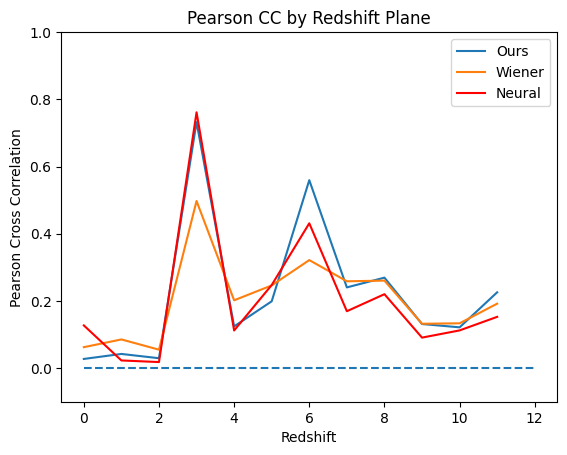

In [27]:
plt.title('Pearson CC by Redshift Plane')

plt.plot(pcc_ours, label='Ours')
plt.plot(pcc_wien, label='Wiener')
plt.plot(pcc_neur, label='Neural', c='r')
plt.hlines(0., 0, 12, linestyles=['dashed'])

plt.ylabel('Pearson Cross Correlation')
plt.xlabel('Redshift')

plt.ylim([-0.1, 1])

plt.legend()
plt.show()

In [28]:
print("==============================================================")
print('PCC 2D: ')
print('Ours: ', get_pcc(k_gt, k_dm))
# print('DAPS: ', get_pcc(k_gt, k_daps))
print('Wiener: ', get_pcc(k_gt, k_wiener))
print('Neural: ', get_pcc(k_gt, k_nn.mean(0)))

PCC 2D: 
Ours:  0.8746543302640226
Wiener:  0.7661401458426372
Neural:  0.8567083267225969


In [29]:
print("==============================================================")
print('PCC: ')
print('Ours: ', lightcone_avg(get_pcc, density_gt[..., :12], ddpm_recon[..., :12]))
print('Wiener: ', lightcone_avg(get_pcc, density_gt[..., :12], wiener_recon[..., :12]))
print('Neural: ', lightcone_avg(get_pcc, density_gt[..., :12], densities_mean[..., :12]))

print("==============================================================")
print('PCC Blur: ')
print('Ours: ', lightcone_avg(get_pcc, density_gt_blur[..., :12], ddpm_recon[..., :12]))
print('Wiener: ', lightcone_avg(get_pcc, density_gt_blur[..., :12], wiener_recon[..., :12]))
print('Neural: ', lightcone_avg(get_pcc, density_gt_blur[..., :12], densities_mean[..., :12]))

print("==============================================================")
print('PCC Blur 2: ')
print('Ours: ', lightcone_avg(get_pcc, density_gt_blur[..., :12], ddpm_blur[..., :12]))
print('Wiener: ', lightcone_avg(get_pcc, density_gt_blur[..., :12], wien_blur[..., :12]))
print('Neural: ', lightcone_avg(get_pcc, density_gt_blur[..., :12], neur_blur[..., :12]))

print("==============================================================")
print('MSE: ')
print('Ours: ', lightcone_avg(get_mse, density_gt[..., :12], ddpm_recon[..., :12]))
print('Wiener: ', lightcone_avg(get_mse, density_gt[..., :12], wiener_recon[..., :12]))
print('Neural: ', lightcone_avg(get_mse, density_gt[..., :12], densities_mean[..., :12]))

print("==============================================================")
print('PSNR: ')
print('Ours: ', lightcone_avg(get_psnr, density_gt[..., :12], ddpm_recon[..., :12]))
print('Wiener: ', lightcone_avg(get_psnr, density_gt[..., :12], wiener_recon[..., :12]))
print('Neural: ', lightcone_avg(get_psnr, density_gt[..., :12], densities_mean[..., :12]))


PCC: 
Ours:  0.22512521507090624
Wiener:  0.20379789102971071
Neural:  0.20539207710352367
PCC Blur: 
Ours:  0.7544701686459964
Wiener:  0.6627837330051661
Neural:  0.667217659957054
PCC Blur 2: 
Ours:  0.8280632752434104
Wiener:  0.7065026808375752
Neural:  0.786943610738761
MSE: 
Ours:  1.5116812
Wiener:  1.5451053
Neural:  1.4994673
PSNR: 
Ours:  27.717291514078777
Wiener:  27.838664253552754
Neural:  27.847421765327454


In [30]:
def optimal_blur(density_gt, density_recon, sigma_xys, sigma_zs):
    optimal_cc = -100.
    optimal_density_gt = None 
    optimal_sig_xy = None 
    optimal_sig_z = None
    for sig_xy in sigma_xys: 
        for sig_z in sigma_zs: 
            density_gt_blurred = gaussian_filter(density_gt, (sig_xy, sig_xy, sig_z))
            cc = get_pcc_avg(density_gt_blurred[..., :12], density_recon[..., :12])
            if cc > optimal_cc: 
                optimal_cc = cc
                optimal_density_gt = density_gt_blurred 
                optimal_sig_xy = sig_xy 
                optimal_sig_z = sig_z 
    return optimal_cc, optimal_density_gt, optimal_sig_xy, optimal_sig_z

def optimal_blur_curve(density_gt, density_recon, sigma_xys, sigma_zs):
    ccs = []
    for sig_xy in sigma_xys: 
        for sig_z in sigma_zs: 
            density_gt_blurred = gaussian_filter(density_gt, (sig_xy, sig_xy, sig_z))
            density_recon_blurred = gaussian_filter(density_recon, (sig_xy, sig_xy, sig_z))
            cc = get_pcc_avg(density_gt_blurred[..., :12], density_recon_blurred[..., :12])
            ccs.append(cc)
    return ccs

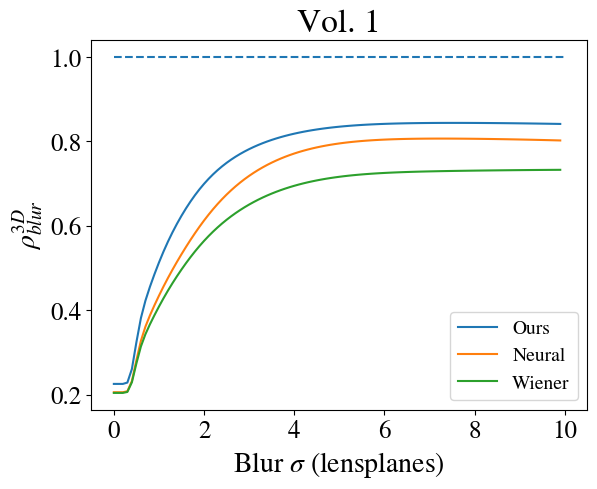

In [36]:
sigma_xys = [0.]
sigma_zs = jnp.linspace(0., 10., num=100, endpoint=False)

ccs_nn = optimal_blur_curve(density_gt, densities_mean, sigma_xys, sigma_zs)
ccs_wn = optimal_blur_curve(density_gt, wiener_recon, sigma_xys, sigma_zs)
ccs_dm = optimal_blur_curve(density_gt, ddpm_recon, sigma_xys, sigma_zs)

plt.hlines(1, 0, 10, linestyles=['dashed'])
plt.plot(sigma_zs, ccs_dm, label='Ours')
plt.plot(sigma_zs, ccs_nn, label='Neural')
plt.plot(sigma_zs, ccs_wn, label='Wiener')

plt.xlabel(r'Blur $\sigma$ (lensplanes)', fontsize=20)
plt.ylabel(r'$\rho_{blur}^{3D}$', fontsize=20)

plt.title('Vol. 1', fontsize=24)
plt.legend(fontsize=14, loc='lower right')
plt.savefig('../jwst_figs/blur_res_1.svg', bbox_inches='tight')
plt.show()

In [32]:
sigma_xys = [0.]
sigma_zs = jnp.linspace(0., 10., num=100, endpoint=False)

optimal_cc_nn, _, _, optimal_sig_z_nn = optimal_blur(density_gt, densities_mean, sigma_xys, sigma_zs)
optimal_cc_wn, _, _, optimal_sig_z_wn = optimal_blur(density_gt, wiener_recon, sigma_xys, sigma_zs)
optimal_cc_dm, _, _, optimal_sig_z_dm = optimal_blur(density_gt, ddpm_recon, sigma_xys, sigma_zs)

print(optimal_sig_z_nn, optimal_sig_z_nn * 164.5, optimal_cc_nn)
print(optimal_sig_z_wn, optimal_sig_z_wn * 164.5, optimal_cc_wn)
print(optimal_sig_z_dm, optimal_sig_z_dm * 164.5, optimal_cc_dm)

min_sig = jnp.min(jnp.array([optimal_sig_z_nn, optimal_sig_z_wn, optimal_sig_z_dm]))
density_gt_min_sig = gaussian_filter(density_gt, (0, 0, min_sig))

print(get_pcc_avg(density_gt_min_sig[..., :12], densities_mean[..., :12]))
print(get_pcc_avg(density_gt_min_sig[..., :12], wiener_recon[..., :12]))
print(get_pcc_avg(density_gt_min_sig[..., :12], ddpm_recon[..., :12]))

5.1 838.95 0.6665521785965739
5.2 855.39996 0.6613098058872802
3.9999998 657.99994 0.7473216089844935
0.6596236421928626
0.6538725162449414
0.7473216089844935
